# 01 · Data exploration

**Question.** What do the three data sources hold over the study region, in which units and with which gaps, and how much forecast history is there?

**Method.** Regional subsets are read from the local cache: the full 2016–2025 precipitation archive, sample days of satellite frames and forecast runs, and a scan of the forecast archive. Nothing here touches the network.

**Answer.** The target is a 15-minute rain *rate*, complete over ten years (350,657 frames, no missing values), dry in 93.5 % of cell-frames and at or above 5 mm/h in 0.34 %. Rain over land peaks at 14–15 UTC, most sharply in the Alps. The product shows *less* precipitation above 1000 m than over the plains, the opposite of gauge climatologies, which marks a weakness of the target in high terrain. All 1,014 forecast runs at 00 and 12 UTC since July 2025 are archived publicly; convective precipitation appears with model version 2 on 2026-05-12.

In [1]:
import dask
import dask.array
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from arena.config import load_config
from arena.data import cache
from arena.data.sampling import STRATA, strata, stratum_means
from arena.data.sources.aifs_ens import deaccumulate

cfg = load_config()
root = cache.cache_root(cfg)
plt.rcParams.update(
    {"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9}
)
pd.options.display.float_format = "{:,.2f}".format

## 1. Sources and regional subsets

Everything below is read from the local cache, which holds the study region only
(6–14° E, 43.5–47.5° N). The cache is filled with `arena data ...` and
`arena archive ...`; see the README. For this notebook it holds the full
2016–2025 precipitation archive and a few sample days and runs of the rest.

In [2]:
rain = cache.open_cached(cfg, "pardig").precipitation
sat = cache.open_cached(cfg, "satweave")
runs = cache.open_cached(cfg, "aifs_ens")
elevation = xr.open_zarr(
    root / "static" / "elevation.zarr", consolidated=False
).elevation.load()


def span(times) -> str:
    first, last = pd.Timestamp(times[0]), pd.Timestamp(times[-1])
    return f"{first:%Y-%m-%d %H:%M} to {last:%Y-%m-%d %H:%M}"


def grid(obj) -> str:
    return f"{obj.sizes['latitude']} x {obj.sizes['longitude']}"


pd.DataFrame(
    {
        "variables": ["precipitation", ", ".join(sat.data_vars), "tp, cp"],
        "units": [
            rain.attrs["units"],
            sat.mosaic_11200_nm.attrs.get("units", "K"),
            runs.tp.attrs["units"],
        ],
        "grid points": [grid(rain), grid(sat), grid(runs)],
        "time steps cached": [
            rain.sizes["time"],
            sat.sizes["time"],
            runs.sizes["init_time"],
        ],
        "cached span (UTC)": [
            span(rain.time.values),
            span(sat.time.values),
            span(runs.init_time.values),
        ],
    },
    index=["PARDIG (target)", "SatWeave (covariates)", "AIFS ENS (forecast runs)"],
)

,variables,units,grid points,time steps cached,cached span (UTC)
PARDIG (target),precipitation,mm h-1,41 x 81,350849,2016-01-01 07:45 to 2026-06-02 23:45
SatWeave (covariates),"mosaic_11200_nm, mosaic_6200_nm",K,41 x 81,48,2025-07-15 00:00 to 2026-06-01 23:00
AIFS ENS (forecast runs),"tp, cp",mm,17 x 33,4,2026-05-11 00:00 to 2026-06-01 12:00


## 2. Units and conversions

PARDIG stores an **instantaneous rate in m/h** every 15 minutes, not an
accumulation. The cache converts it to mm/h once (factor 1000). A total over a
period is the mean rate over its frames times its length. The forecast `tp` is
different again: mm accumulated since the start of the run.

One pass over the ten-year archive gives every statistic used in sections 2 to 5.

In [3]:
archive = rain.sel(time=slice("2016", "2025"))
labels = strata(elevation, cfg)
thresholds = [0.1, 1.0, 5.0, 20.0]
edges = np.concatenate([[0.0], np.logspace(-2, 2, 81)])

lazy = {
    "mean": archive.mean("time"),
    "max": archive.max("time"),
    "p99": archive.quantile(0.99, "time"),
    "missing": archive.isnull().sum(),
    "dry": (archive == 0).mean(),
    "exceed": xr.concat([(archive >= t).mean() for t in thresholds], "threshold"),
    "by_stratum": stratum_means(archive, labels),
    "histogram": dask.array.histogram(archive.data, bins=edges)[0],
}
stats = dict(zip(lazy, dask.compute(*lazy.values()), strict=True))

hours_per_year = 24 * 365.25
annual = stats["mean"] * hours_per_year
print(
    f"source unit factor      : x{cfg.data.pardig.rate_to_mm_per_hour:g} (m/h to mm/h)"
)
print(
    f"largest rate in archive : {float(stats['max'].max()):.1f} mm/h (the product caps rates at 75 mm/h)"
)
print(
    f"mean annual total       : {float(annual.mean()):.0f} mm, from {float(annual.min()):.0f} to {float(annual.max()):.0f} mm across cells"
)

source unit factor      : x1000 (m/h to mm/h)
largest rate in archive : 75.0 mm/h (the product caps rates at 75 mm/h)
mean annual total       : 917 mm, from 171 to 2003 mm across cells


## 3. Missing data

In [4]:
expected = pd.date_range(archive.time.values[0], archive.time.values[-1], freq="15min")
steps = np.diff(archive.time.values) / np.timedelta64(1, "m")
print(
    f"frames in archive  : {archive.sizes['time']:,} of {len(expected):,} expected at 15-minute steps"
)
print(f"irregular steps    : {int((steps != 15).sum())}")
print(f"missing values     : {int(stats['missing'])} of {archive.size:,}")
print(
    f"first frame        : {pd.Timestamp(archive.time.values[0]):%Y-%m-%d %H:%M} (the product starts at 07:45, not at midnight)"
)

days = pd.DataFrame(
    {
        "frames": [
            int(rain.sel(time=day).sizes["time"])
            for day in ("2026-06-01", "2026-06-02")
        ],
        "missing values": [
            int(rain.sel(time=day).isnull().sum())
            for day in ("2026-06-01", "2026-06-02")
        ],
    },
    index=["2026-06-01", "2026-06-02"],
)
days.rename_axis("sample day of 2026 frames")

frames in archive  : 350,657 of 350,657 expected at 15-minute steps
irregular steps    : 0
missing values     : 0 of 1,164,531,897
first frame        : 2016-01-01 07:45 (the product starts at 07:45, not at midnight)


,frames,missing values
sample day of 2026 frames,,
2026-06-01,96,0
2026-06-02,96,0


## 4. Terrain strata and precipitation climatology

Cells are grouped by terrain height (Copernicus DEM, sampled at the cell
centre): sea, coast (land below 300 m within 0.3° of the sea), plains (other
land below 300 m), pre-Alps (300–1000 m) and Alps (1000 m and above).

,cells,mean annual total (mm)
sea,508,1112
coast,266,1114
plains,512,1010
pre_alps,873,1013
alps,1162,674


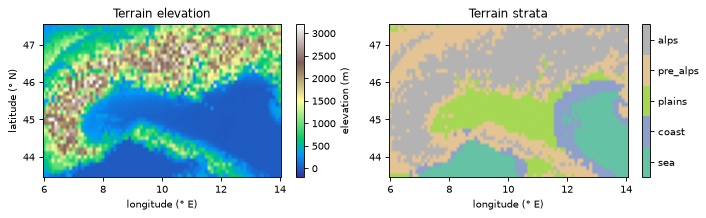

In [5]:
extent = [
    cfg.region.lon_min - 0.05,
    cfg.region.lon_max + 0.05,
    cfg.region.lat_min - 0.05,
    cfg.region.lat_max + 0.05,
]
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
image = axes[0].imshow(
    elevation,
    origin="lower",
    extent=extent,
    cmap="terrain",
    vmin=-200,
    vmax=3200,
    aspect="auto",
)
fig.colorbar(image, ax=axes[0], label="elevation (m)")
axes[0].set_title("Terrain elevation")
image = axes[1].imshow(
    labels,
    origin="lower",
    extent=extent,
    cmap=plt.get_cmap("Set2", len(STRATA)),
    vmin=-0.5,
    vmax=len(STRATA) - 0.5,
    aspect="auto",
)
bar = fig.colorbar(image, ax=axes[1], ticks=range(len(STRATA)))
bar.ax.set_yticklabels(STRATA)
axes[1].set_title("Terrain strata")
for ax in axes:
    ax.grid(False)
    ax.set_xlabel("longitude (° E)")
axes[0].set_ylabel("latitude (° N)")
plt.tight_layout()

counts = pd.Series(
    {name: int((labels == i).sum()) for i, name in enumerate(STRATA)}, name="cells"
)
by_stratum = stats["by_stratum"].to_pandas().T
pd.DataFrame(
    {"cells": counts, "mean annual total (mm)": by_stratum.mean() * hours_per_year}
).round(0).astype(int)

,wettest hour (UTC),wettest month,peak-to-mean ratio of the diurnal cycle
stratum,,,
sea,7,11,1.07
coast,14,5,1.24
plains,15,5,1.28
pre_alps,14,6,1.40
alps,15,7,1.61


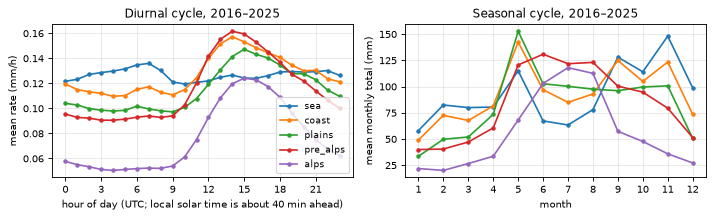

In [6]:
diurnal = by_stratum.groupby(by_stratum.index.hour).mean()
seasonal = by_stratum.groupby(by_stratum.index.month).mean() * 24 * 30.44
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
diurnal.plot(ax=axes[0], marker=".")
axes[0].set(
    title="Diurnal cycle, 2016–2025",
    xlabel="hour of day (UTC; local solar time is about 40 min ahead)",
    ylabel="mean rate (mm/h)",
    xticks=range(0, 24, 3),
)
seasonal.plot(ax=axes[1], marker=".", legend=False)
axes[1].set(
    title="Seasonal cycle, 2016–2025",
    xlabel="month",
    ylabel="mean monthly total (mm)",
    xticks=range(1, 13),
)
axes[0].legend(title=None, fontsize=8)
plt.tight_layout()

peak = pd.DataFrame(
    {
        "wettest hour (UTC)": diurnal.idxmax(),
        "wettest month": seasonal.idxmax(),
        "peak-to-mean ratio of the diurnal cycle": diurnal.max() / diurnal.mean(),
    }
)
peak

## 5. Zero inflation and the heavy tail

Most frames are dry, and most of the water falls in a small share of the wet
ones. Both matter for training (loss dominated by zeros) and for scoring
(thresholds at 0.1, 1 and 5 mm/h are rare events).

exactly zero: 93.5% of cell-frames
>= 0.1 mm/h    6.456%
>= 1 mm/h      2.570%
>= 5 mm/h      0.339%
>= 20 mm/h     0.037%


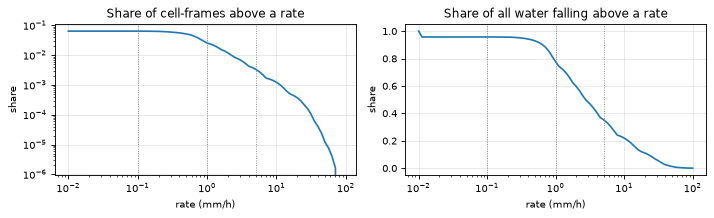

In [7]:
exceed = pd.Series(
    stats["exceed"].values,
    index=[f">= {t:g} mm/h" for t in thresholds],
    name="share of cell-frames",
)
print(f"exactly zero: {float(stats['dry']):.1%} of cell-frames")
print(exceed.map("{:.3%}".format).to_string())

counts_hist = stats["histogram"].astype(float)
survival = 1 - np.cumsum(counts_hist) / counts_hist.sum()
water = np.cumsum((counts_hist * (edges[:-1] + edges[1:]) / 2)[::-1])[::-1]
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
axes[0].loglog(edges[1:-1], survival[:-1])
axes[0].set(
    title="Share of cell-frames above a rate", xlabel="rate (mm/h)", ylabel="share"
)
axes[1].semilogx(edges[1:], water[:] / water[0])
axes[1].set(
    title="Share of all water falling above a rate",
    xlabel="rate (mm/h)",
    ylabel="share",
)
for ax in axes:
    for t in (0.1, 1, 5):
        ax.axvline(t, color="grey", lw=0.8, ls=":")
plt.tight_layout()

## 6. Maps of the mean and of the 99th percentile

black line: 1000 m contour
99th percentile ranges from 0.71 to 5.10 mm/h across cells


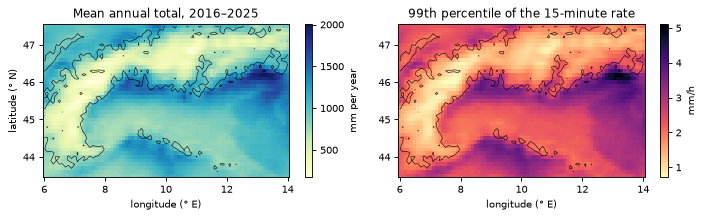

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
for ax, field, title, label, cmap in (
    (axes[0], annual, "Mean annual total, 2016–2025", "mm per year", "YlGnBu"),
    (axes[1], stats["p99"], "99th percentile of the 15-minute rate", "mm/h", "magma_r"),
):
    image = ax.imshow(field, origin="lower", extent=extent, cmap=cmap, aspect="auto")
    fig.colorbar(image, ax=ax, label=label)
    ax.contour(
        elevation.longitude,
        elevation.latitude,
        elevation,
        levels=[1000],
        colors="k",
        linewidths=0.5,
    )
    ax.set(title=title, xlabel="longitude (° E)")
    ax.grid(False)
axes[0].set_ylabel("latitude (° N)")
plt.tight_layout()
print("black line: 1000 m contour")
print(
    f"99th percentile ranges from {float(stats['p99'].min()):.2f} to {float(stats['p99'].max()):.2f} mm/h across cells"
)

The driest cells of the map are the highest ones, and the Alps stratum has the
lowest annual total in the table of section 4. Rain-gauge climatologies of
the region show the opposite along the Alpine rim. The product's
documentation reports lower skill over the Alps and for snowfall, so the
low totals above 1000 m are most likely an underestimate by the target, not
a feature of the climate. Scores in the Alps stratum measure agreement with
this product, and have to be read with that in mind.

## 7. Satellite covariates

Two bands are kept: the 11.2 µm infrared window, where a cold value means a
high cloud top, and the 6.2 µm water-vapour band. Over Europe the 10.4 µm
window band is empty, because Meteosat does not carry it. The archive has
30-minute steps to 2025 and hourly frames from 2026; hourly steps are cached
for both.

In [9]:
bands = pd.DataFrame(
    {
        name: {
            "hours cached": sat.sizes["time"],
            "min (K)": float(sat[name].min()),
            "mean (K)": float(sat[name].mean()),
            "max (K)": float(sat[name].max()),
            "missing share": float(sat[name].isnull().mean()),
        }
        for name in sat.data_vars
    }
).T
bands

,hours cached,min (K),mean (K),max (K),missing share
mosaic_11200_nm,48.00,206.38,277.95,307.14,0.00
mosaic_6200_nm,48.00,207.70,233.30,243.74,0.00


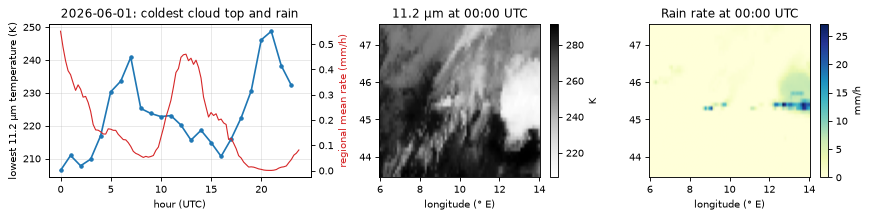

In [10]:
day = "2026-06-01"
window = sat.mosaic_11200_nm.sel(time=day).load()
coldest = window.min(("latitude", "longitude")).to_series()
rate = rain.sel(time=day).mean(("latitude", "longitude")).to_series()
hour = coldest.idxmin()

fig, axes = plt.subplots(
    1, 3, figsize=(11, 2.8), gridspec_kw={"width_ratios": [1.3, 1, 1]}
)
axes[0].plot(coldest.index.hour, coldest.values, color="tab:blue", marker=".")
axes[0].set(
    title=f"{day}: coldest cloud top and rain",
    xlabel="hour (UTC)",
    ylabel="lowest 11.2 µm temperature (K)",
)
twin = axes[0].twinx()
twin.plot(rate.index.hour + rate.index.minute / 60, rate.values, color="tab:red", lw=1)
twin.set_ylabel("regional mean rate (mm/h)", color="tab:red")
twin.grid(False)
image = axes[1].imshow(
    window.sel(time=hour), origin="lower", extent=extent, cmap="Greys", aspect="auto"
)
fig.colorbar(image, ax=axes[1], label="K")
axes[1].set(title=f"11.2 µm at {hour:%H:%M} UTC", xlabel="longitude (° E)")
image = axes[2].imshow(
    rain.sel(time=hour), origin="lower", extent=extent, cmap="YlGnBu", aspect="auto"
)
fig.colorbar(image, ax=axes[2], label="mm/h")
axes[2].set(title=f"Rain rate at {hour:%H:%M} UTC", xlabel="longitude (° E)")
for ax in axes[1:]:
    ax.grid(False)
plt.tight_layout()

## 8. Forecast archive: coverage and model versions

The public mirrors of ECMWF open data keep every AIFS ensemble run since the
first operational one. The scan below read one small index file per run at 00
and 12 UTC. Runs that list convective precipitation (`cp`) come from model
version 2.

runs scanned       : 1,014 (2025-07-01 12 UTC to 2026-11-20 00 UTC)
present on mirrors : 1,014
first run with cp  : 2026-05-12 12 UTC


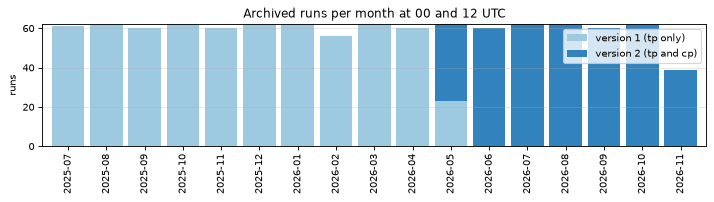

In [11]:
coverage = pd.read_csv(
    root / "aifs_ens" / "coverage.csv", parse_dates=["init_time"]
).set_index("init_time")
print(
    f"runs scanned       : {len(coverage):,} ({coverage.index[0]:%Y-%m-%d %H} UTC to {coverage.index[-1]:%Y-%m-%d %H} UTC)"
)
print(f"present on mirrors : {int(coverage.available.sum()):,}")
print(f"first run with cp  : {coverage.index[coverage.has_cp][0]:%Y-%m-%d %H} UTC")

monthly = pd.DataFrame(
    {
        "version 1 (tp only)": (coverage.available & ~coverage.has_cp)
        .resample("MS")
        .sum(),
        "version 2 (tp and cp)": coverage.has_cp.resample("MS").sum(),
    }
)
monthly.index = monthly.index.strftime("%Y-%m")
ax = monthly.plot.bar(
    stacked=True, figsize=(9, 2.6), width=0.85, color=["#9ecae1", "#3182bd"]
)
ax.set(title="Archived runs per month at 00 and 12 UTC", xlabel="", ylabel="runs")
ax.grid(axis="x")
plt.tight_layout()

In [12]:
cached = pd.DataFrame(
    {
        "model version": runs.model_version.values,
        "members": runs.sizes["member"],
        "steps (h)": f"{int(runs.step[0])} to {int(runs.step[-1])}",
        "has cp": runs.cp.notnull()
        .any(("member", "step", "latitude", "longitude"))
        .values,
        "largest tp at 60 h (mm)": runs.tp.isel(step=-1)
        .max(("member", "latitude", "longitude"))
        .values,
    },
    index=pd.DatetimeIndex(runs.init_time.values, name="run (UTC)").strftime(
        "%Y-%m-%d %H"
    ),
)
cached

,model version,members,steps (h),has cp,largest tp at 60 h (mm)
run (UTC),,,,,
2026-05-11 00,1,51,6 to 60,False,89.57
2026-05-11 12,1,51,6 to 60,False,63.22
2026-06-01 00,2,51,6 to 60,True,104.67
2026-06-01 12,2,51,6 to 60,True,114.14


One run against the observations, as an illustration of the two quantities
side by side (regional means; this is not an evaluation). Forecast totals per
6 hours are differences of the accumulations; observed totals are the mean
rate of the 24 frames in each window times 6 hours.

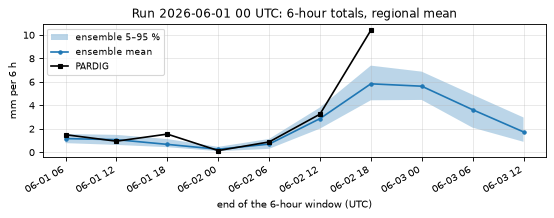

In [13]:
init = pd.Timestamp("2026-06-01 00:00")
totals = (
    deaccumulate(runs[["tp"]].sel(init_time=init))
    .tp.mean(("latitude", "longitude"))
    .load()
)
valid = init + pd.to_timedelta(totals.step.values, unit="h")
observed = (
    rain.sel(time=slice(init + pd.Timedelta("15min"), None))
    .mean(("latitude", "longitude"))
    .to_series()
    .resample("6h", closed="right", label="right")
    .agg(["mean", "count"])
)
observed = observed[observed["count"] == 24]["mean"] * 6

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.fill_between(
    valid,
    totals.quantile(0.05, "member"),
    totals.quantile(0.95, "member"),
    alpha=0.3,
    label="ensemble 5–95 %",
)
ax.plot(valid, totals.mean("member"), marker=".", label="ensemble mean")
ax.plot(observed.index, observed.values, color="k", marker="s", ms=4, label="PARDIG")
ax.set(
    title="Run 2026-06-01 00 UTC: 6-hour totals, regional mean",
    ylabel="mm per 6 h",
    xlabel="end of the 6-hour window (UTC)",
)
ax.legend(fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()

## 9. What this means for the benchmark

- **Target.** A 15-minute rate, complete over ten years, dry most of the time
  and with a heavy tail. It is itself a model estimate and uses satellite
  frames up to 90 minutes after its valid time, so the benchmark is a hindcast
  and results near zero lead time need the sensitivity run described in
  `docs/methodology.md`. Above 1000 m it probably underestimates
  precipitation.
- **Covariates.** Hourly, two bands, complete over the region.
- **Forecasts.** Available from July 2025 only, in two model versions. The
  common test window (2026-05-13 to 2026-11-15) lies entirely in version 2;
  models that use forecast covariates are trained on version 1.
- **Splits and units** are fixed in `configs/data.yaml` and explained in
  `docs/methodology.md`.